
# 🛍️ Customer Segmentation Analysis
### Understanding Customer Behaviour Through RFM & K-Means

**Objective:** Segment e-commerce customers based on purchasing behaviour to support targeted marketing strategies.

**Methodology:** RFM Analysis • Data Cleaning • Feature Scaling • K-Means Clustering

**Technology Stack:** Python | Pandas | Scikit-learn | Matplotlib | Seaborn

**Expected Outcome:** Identify valuable, loyal, occasional, and inactive customer groups and recommend suitable marketing actions.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="viridis")

DATA_PATH = Path("data/Online Retail.xlsx")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

Libraries imported successfully.
Output folder: C:\Users\Santhya S\Downloads\Customer_Segmentation_Analysis\outputs


In [4]:
df = pd.read_excel(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

In [5]:

# Inspect the dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values per column:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate rows: 5268

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

# Create a clean copy of the dataset
df.columns = df.columns.str.strip()

required_columns = [
    "InvoiceNo", "InvoiceDate", "Quantity",
    "UnitPrice", "CustomerID", "StockCode"
]

missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Correct data types
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Remove records without essential customer or transaction information
df = df.dropna(
    subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

# Exclude cancelled invoices and invalid purchase quantities/prices
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")].copy()
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

# Standardise customer IDs and calculate sales value
df["CustomerID"] = df["CustomerID"].astype(int)
df["SalesValue"] = df["Quantity"] * df["UnitPrice"]

print("Cleaning completed successfully!")
print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.head())


Cleaning completed successfully!
Cleaned dataset shape: (392692, 9)
Unique customers: 4338
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [7]:

# Export cleaned transaction data
cleaned_path = OUTPUT_DIR / "cleaned_retail_data.csv"
df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:", cleaned_path.resolve())


Cleaned dataset saved to: C:\Users\Santhya S\Downloads\Customer_Segmentation_Analysis\outputs\cleaned_retail_data.csv


In [8]:

# Customer-level descriptive statistics
customer_stats = df.groupby("CustomerID").agg(
    TotalSpend=("SalesValue", "sum"),
    TotalUnits=("Quantity", "sum"),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    UniqueProducts=("StockCode", "nunique"),
    PurchaseFrequency=("InvoiceNo", "nunique")
)

customer_stats["AveragePurchaseValue"] = (
    customer_stats["TotalSpend"] / customer_stats["PurchaseFrequency"]
)

# Historical spend is a proxy, not a prediction of future lifetime value
customer_stats["HistoricalCustomerValue"] = customer_stats["TotalSpend"]

print("Customer purchasing statistics:")
display(customer_stats.describe().T.round(2))

print(
    "Average purchase value:",
    round(customer_stats["AveragePurchaseValue"].mean(), 2)
)
print(
    "Average purchase frequency:",
    round(customer_stats["PurchaseFrequency"].mean(), 2),
    "invoices per customer"
)
print(
    "Average historical customer spend:",
    round(customer_stats["HistoricalCustomerValue"].mean(), 2)
)

customer_stats.to_csv(
    OUTPUT_DIR / "customer_descriptive_statistics.csv"
)


Customer purchasing statistics:


,count,mean,min,25%,50%,75%,max,std
TotalSpend,4338.0,2048.688081,3.75,306.4825,668.57,1660.5975,280206.02,8985.23022
TotalUnits,4338.0,1187.644537,1.0,159.0,378.0,989.75,196915.0,5043.619654
FirstPurchase,4338,2011-04-30 17:06:50.857538048,2010-12-01 08:26:00,2011-01-17 11:13:15,2011-04-05 09:52:30,2011-08-19 10:11:30,2011-12-09 12:16:00,NaN
LastPurchase,4338,2011-09-08 11:38:59.045643008,2010-12-01 09:53:00,2011-07-20 19:18:00,2011-10-20 10:40:30,2011-11-22 11:05:45,2011-12-09 12:50:00,NaN
UniqueProducts,4338.0,61.501153,1.0,16.0,35.0,77.0,1787.0,85.366768
PurchaseFrequency,4338.0,4.272015,1.0,1.0,2.0,5.0,209.0,7.697998
AveragePurchaseValue,4338.0,417.645735,3.45,177.867083,291.94,428.280625,84236.25,1796.511343
HistoricalCustomerValue,4338.0,2048.688081,3.75,306.4825,668.57,1660.5975,280206.02,8985.23022


Average purchase value: 417.65
Average purchase frequency: 4.27 invoices per customer
Average historical customer spend: 2048.69


In [9]:

# Create RFM features for each customer

snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("SalesValue", "sum")
)

rfm["Recency"] = (
    snapshot_date - rfm["LastPurchase"].dt.normalize()
).dt.days

rfm = rfm[["Recency", "Frequency", "Monetary"]].copy()

print("RFM table created successfully!")
print("Number of customers:", len(rfm))
display(rfm.head(10))
display(rfm.describe().round(2))


RFM table created successfully!
Number of customers: 4338


C:\Users\Santhya S\AppData\Local\Temp\ipykernel_11744\1821133493.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1797.24
12349,19,1,1757.55
12350,311,1,334.40
12352,37,8,2506.04
12353,205,1,89.00
12354,233,1,1079.40
12355,215,1,459.40


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.75,5.00,1660.60
max,374.00,209.00,280206.02


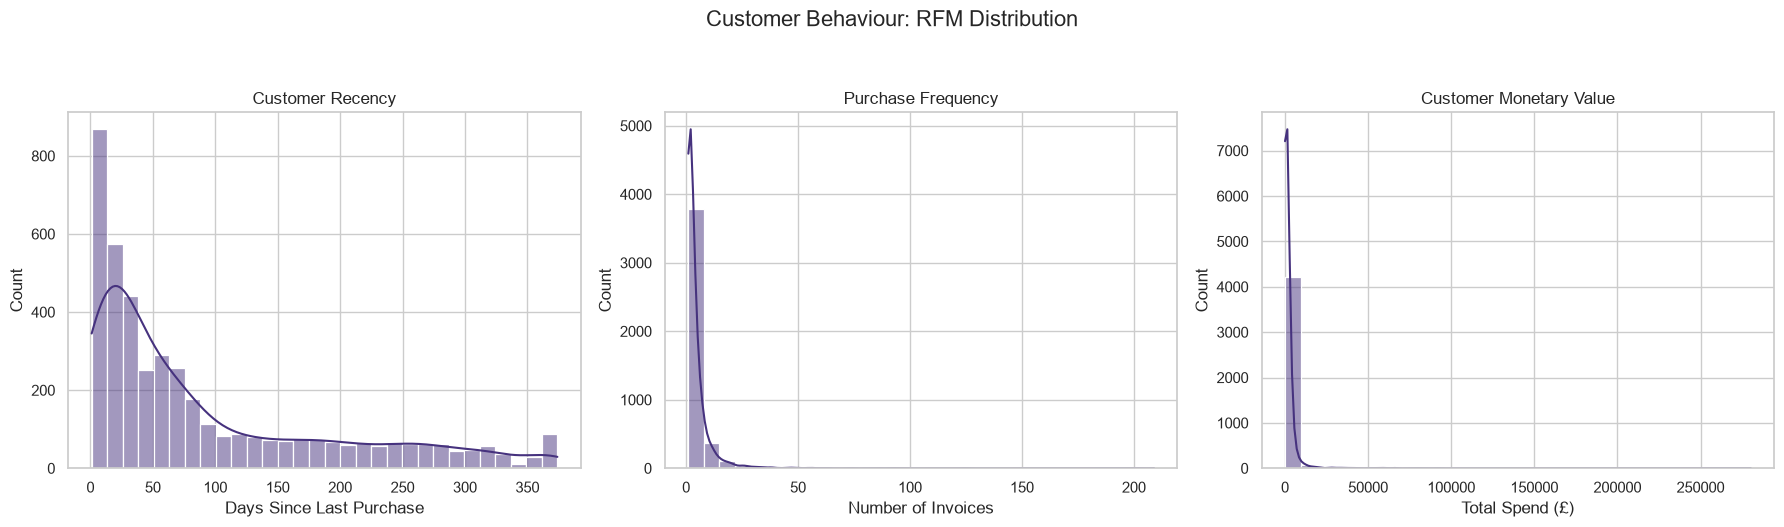

In [10]:

# Distribution of RFM features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=rfm, x="Recency", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Customer Recency")
axes[0].set_xlabel("Days Since Last Purchase")

sns.histplot(data=rfm, x="Frequency", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Purchase Frequency")
axes[1].set_xlabel("Number of Invoices")

sns.histplot(data=rfm, x="Monetary", bins=30, kde=True, ax=axes[2])
axes[2].set_title("Customer Monetary Value")
axes[2].set_xlabel("Total Spend (£)")

plt.suptitle("Customer Behaviour: RFM Distribution", fontsize=16, y=1.05)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


In [11]:

# Transform and standardize RFM features

rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Standardization completed!")
print("Feature matrix shape:", X_scaled.shape)
print("Features used:", rfm_features.columns.tolist())


Standardization completed!
Feature matrix shape: (4338, 3)
Features used: ['Recency', 'Frequency', 'Monetary']


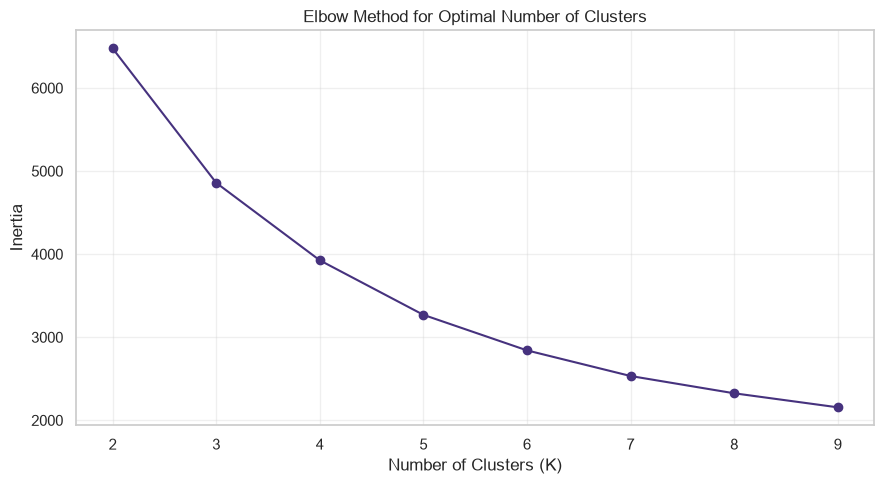

In [12]:

# Elbow Method for selecting K

k_values = range(2, 10)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "elbow_method.png", dpi=300, bbox_inches="tight")
plt.show()


In [13]:

# Fit the K-Means clustering model

BEST_K = 4  # Change this after reviewing the elbow plot

kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

silhouette = silhouette_score(
    X_scaled,
    rfm["Cluster"],
    sample_size=min(10000, len(rfm)),
    random_state=42
)

print("Chosen number of clusters:", BEST_K)
print("Silhouette score:", round(silhouette, 3))
print("Cluster assignment completed!")
display(rfm.head())


Chosen number of clusters: 4
Silhouette score: 0.333
Cluster assignment completed!


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,1
12347,3,7,4310.00,3
12348,76,4,1797.24,1
12349,19,1,1757.55,0
12350,311,1,334.40,2


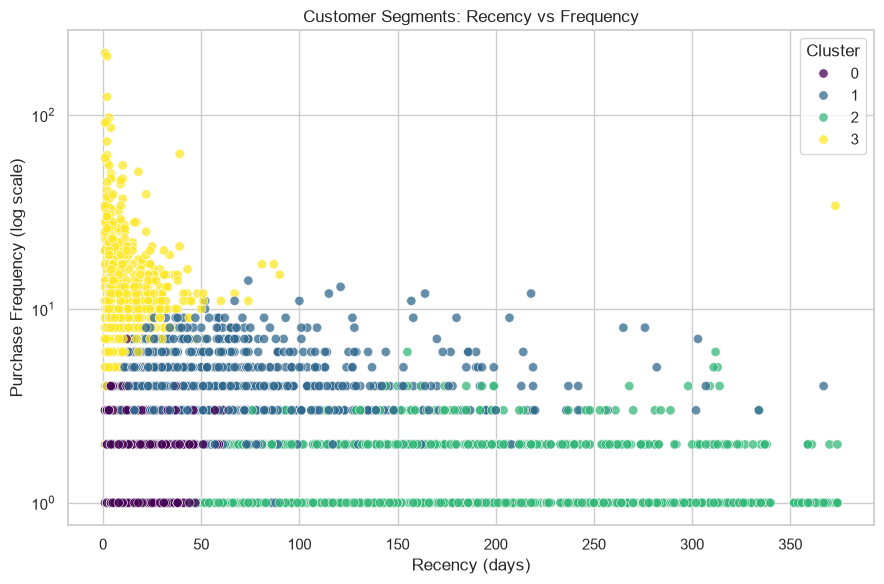

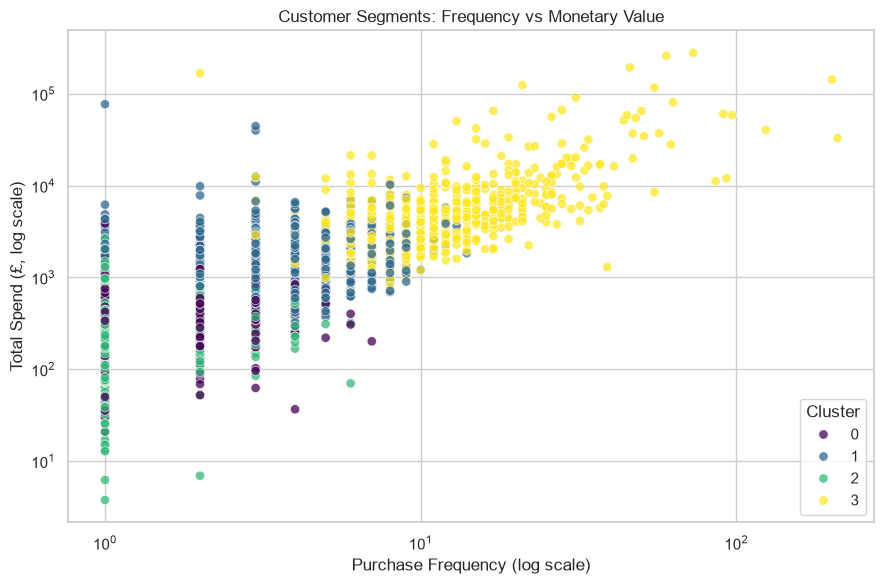

In [14]:

# Visualization 1: Recency vs Frequency

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="viridis",
    alpha=0.75,
    s=45
)
plt.yscale("log")
plt.title("Customer Segments: Recency vs Frequency")
plt.xlabel("Recency (days)")
plt.ylabel("Purchase Frequency (log scale)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_recency_frequency.png", dpi=300, bbox_inches="tight")
plt.show()

# Visualization 2: Frequency vs Monetary Value

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.75,
    s=45
)
plt.xscale("log")
plt.yscale("log")
plt.title("Customer Segments: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency (log scale)")
plt.ylabel("Total Spend (£, log scale)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_frequency_monetary.png", dpi=300, bbox_inches="tight")
plt.show()


In [15]:

# Summarize each cluster

cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median")
).round(2)

cluster_profile["CustomerSharePct"] = (
    cluster_profile["Customers"] / len(rfm) * 100
).round(2)

print("Customer segment profiles:")
display(cluster_profile)

cluster_profile.to_csv(OUTPUT_DIR / "cluster_profiles.csv")


Customer segment profiles:


,Customers,AvgRecency,AvgFrequency,AvgMonetary,MedianMonetary,CustomerSharePct
Cluster,,,,,,
0,897,22.79,1.92,486.06,414.20,20.68
1,1174,65.29,4.19,1822.98,1355.04,27.06
2,1549,192.27,1.35,360.55,303.16,35.71
3,718,12.21,13.64,8011.89,3687.77,16.55


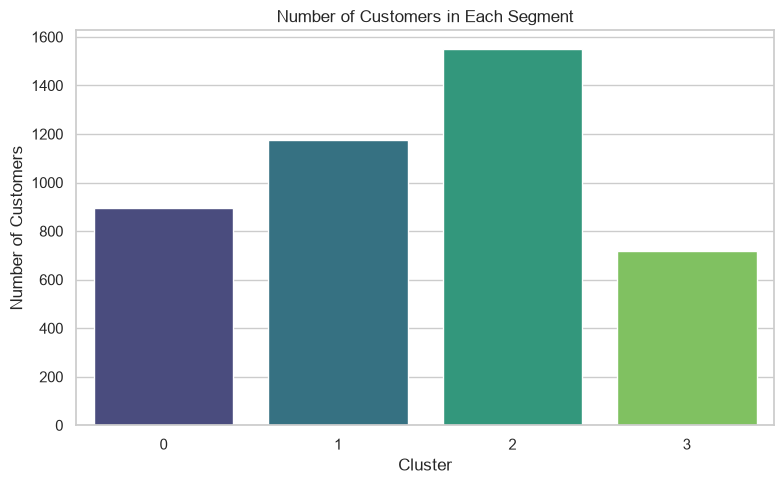

In [16]:

# Bar chart: customers in each cluster

plt.figure(figsize=(8, 5))
sns.barplot(
    x=cluster_profile.index.astype(str),
    y=cluster_profile["Customers"],
    hue=cluster_profile.index.astype(str),
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "customers_per_cluster.png", dpi=300, bbox_inches="tight")
plt.show()


In [17]:

# Save the customer segments and profiles

rfm.to_csv(OUTPUT_DIR / "customer_rfm_segments.csv", index=True)

print("All analysis outputs saved to:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)


All analysis outputs saved to:
- cleaned_retail_data.csv
- cluster_frequency_monetary.png
- cluster_profiles.csv
- cluster_recency_frequency.png
- customer_descriptive_statistics.csv
- customer_rfm_segments.csv
- customers_per_cluster.png
- elbow_method.png
- rfm_distributions.png


In [18]:

# Final customer segment profile
display(cluster_profile.sort_values("AvgMonetary", ascending=False))

# Identify the largest and smallest customer segments
largest_cluster = cluster_profile["Customers"].idxmax()
smallest_cluster = cluster_profile["Customers"].idxmin()

print("Largest customer segment:", largest_cluster)
print("Smallest customer segment:", smallest_cluster)

print("\nCluster summary:")
for cluster_id, row in cluster_profile.iterrows():
    print(
        f"Cluster {cluster_id}: {int(row['Customers'])} customers | "
        f"Average recency: {row['AvgRecency']:.1f} days | "
        f"Average frequency: {row['AvgFrequency']:.2f} invoices | "
        f"Average spend: {row['AvgMonetary']:.2f}"
    )


,Customers,AvgRecency,AvgFrequency,AvgMonetary,MedianMonetary,CustomerSharePct
Cluster,,,,,,
3,718,12.21,13.64,8011.89,3687.77,16.55
1,1174,65.29,4.19,1822.98,1355.04,27.06
0,897,22.79,1.92,486.06,414.20,20.68
2,1549,192.27,1.35,360.55,303.16,35.71


Largest customer segment: 2
Smallest customer segment: 3

Cluster summary:
Cluster 0: 897 customers | Average recency: 22.8 days | Average frequency: 1.92 invoices | Average spend: 486.06
Cluster 1: 1174 customers | Average recency: 65.3 days | Average frequency: 4.19 invoices | Average spend: 1822.98
Cluster 2: 1549 customers | Average recency: 192.3 days | Average frequency: 1.35 invoices | Average spend: 360.55
Cluster 3: 718 customers | Average recency: 12.2 days | Average frequency: 13.64 invoices | Average spend: 8011.89


## Final Results and Business Insights

### Project Outcome

The Customer Segmentation Analysis successfully applied **RFM analysis and K-Means clustering** to group customers based on their purchasing behaviour. The analysis examined recency, purchase frequency, and monetary value to identify meaningful customer segments.

### Key Findings

- **Customer behaviour varies:** Customers differ in how recently and frequently they purchase and how much they spend.
- **Unequal segment sizes:** The cluster distribution shows that some customer groups contain more customers than others.
- **Marketing can be personalized:** Each segment can be targeted with a strategy suited to its observed purchasing behaviour.
- **Data-driven decisions:** RFM metrics and clustering provide a structured way to identify valuable customers and customers who may need re-engagement.

### Marketing Recommendations

1. **High-value, frequent customers:** Offer loyalty rewards, exclusive benefits, and personalized recommendations.
2. **Recent but occasional customers:** Encourage repeat purchases through relevant product suggestions and carefully timed offers.
3. **Previously valuable but inactive customers:** Consider win-back campaigns and personalized reminders.
4. **Low-frequency, low-spend customers:** Test affordable promotions and product bundles to encourage another purchase.

*These segment descriptions should be matched to the actual cluster profiles before presenting them as findings.*

### Conclusion

This project demonstrates how Python, Pandas, Scikit-learn, Matplotlib, and Seaborn can be used to transform retail transaction data into actionable customer segments. The resulting profiles and visualizations can help businesses plan more targeted marketing campaigns and make informed customer-retention decisions.

**Limitation:** Historical spending is used as a proxy for customer value; it is not a prediction of future customer lifetime value. The analysis identifies behavioural patterns but does not prove that a marketing campaign will improve sales.
